<a href="https://colab.research.google.com/github/iindrisw/PROJEK-MACHINE-LEARNING-1/blob/main/P12_Penyiapan_Data_Kelompok1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 12 — Penyiapan Data
## Proyek Akhir Pembelajaran Mesin (INF62325) — Regresi Linear

| | |
|---|---|
| Kelompok | _1_ |
| Anggota | _Maddinatul Dzahra Aulia G (2488010058)_ |
| Anggota | _Euis Fahira Yuningsih (2488010055)_ |
| Anggota | _Indri Setiawati (2488010077)_ |
| Penanggung jawab pertemuan ini | _(Maddinatul Dzahra, Euis Fahira, Indri Setiawati)_ |

---

### Panduan Pertemuan 12

**Tujuan.** Mengubah data mentah Kaggle menjadi data siap latih, dan merancang
seluruh langkah preprocessing ke dalam satu objek `Pipeline`.

**Luaran yang dikumpulkan.** Satu berkas `p12_data.joblib` di folder Drive kelompok,
berisi data yang sudah dibagi latih/uji beserta rancangan `Pipeline`-nya, ditambah
sel keputusan preprocessing yang sudah diisi.

**Yang dinilai pada presentasi progres (10 menit).**

1. Rumusan masalah tiga kalimat, dengan kalimat kedua membuktikan tidak ada kebocoran data.
2. Dua keputusan preprocessing tersulit beserta angka yang mendasarinya — bukan daftar seluruh langkah.
3. Bukti bahwa `train_test_split` dijalankan **sebelum** `Pipeline` dirakit.

**Aturan yang tidak boleh dilanggar.** Tidak ada satu pun transformasi yang dikerjakan
manual pada DataFrame. Semuanya masuk ke dalam `Pipeline`, karena objek itulah yang
nanti dipakai aplikasi web di Pertemuan 14.

**Perkiraan waktu.** 90 menit.

---
## Langkah A — Samakan versi scikit-learn (WAJIB, setiap kali membuka notebook ini)

Colab memulai sesi baru setiap kali notebook dibuka, jadi langkah ini diulang
**di setiap pertemuan**, bukan sekali saja.

Gunanya menyamakan versi scikit-learn di Colab dengan versi yang dipasang
Streamlit Community Cloud. Tanpa ini, model berhasil dilatih tetapi gagal dimuat
di aplikasi web dengan galat
`AttributeError: ... has no attribute '_RemainderColsList'`.

In [52]:
!pip install -q scikit-learn==1.9.1

### Restart dulu, jangan dilewati

Pilih menu **Runtime → Restart session**, lalu jalankan ulang dari sel paling atas.
Tanpa restart, Python masih memakai scikit-learn versi lama yang sudah terlanjur
dimuat ke memori, dan kesalahannya tidak terlihat sampai tahap paling akhir.

In [53]:
import sklearn

print("scikit-learn:", sklearn.__version__)
assert sklearn.__version__ == "1.9.1", (
    "Versi belum sesuai. Jalankan sel pip di atas, lalu Runtime -> Restart session, "
    "lalu jalankan ulang dari sel paling atas."
)
print("Versi sudah sesuai.")

scikit-learn: 1.9.1
Versi sudah sesuai.


---
## Langkah B — Hubungkan Google Drive

Setiap pertemuan menyimpan hasilnya ke satu folder Drive yang sama, lalu pertemuan
berikutnya membacanya dari sana. Dengan begitu pekerjaan tidak hilang saat sesi Colab
berakhir, dan tidak perlu mengulang dari awal tiap minggu.

Folder yang dipakai: `/content/drive/MyDrive/ProyekML_RegresiLinear`

Saat sel di bawah dijalankan, Colab meminta izin mengakses Drive. Pilih akun Google
kelompok, lalu setujui.

In [54]:
import os
from google.colab import drive

drive.mount("/content/drive")

FOLDER = "/content/drive/MyDrive/ProyekML_RegresiLinear"
os.makedirs(FOLDER, exist_ok=True)

print("Folder proyek:", FOLDER)
print("Isi folder   :", sorted(os.listdir(FOLDER)) or "(masih kosong)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder proyek: /content/drive/MyDrive/ProyekML_RegresiLinear
Isi folder   : ['P12_Penyiapan_Data_Kelompok1.ipynb', 'data_mentah.csv', 'p12_data.joblib', 'p13_metrik.json', 'p13_model.joblib']


---
## Langkah C — Unduh data dari Kaggle

Notebook mengunduh datanya sendiri. Dengan begitu dosen dan anggota kelompok lain
bisa menjalankan ulang notebook ini tanpa file titipan, sehingga hasilnya dapat diverifikasi.

In [55]:
import os
import kagglehub
import pandas as pd

SLUG = "larsen0966/student-performance-data-set"
TARGET = "G3"

path = kagglehub.dataset_download(SLUG)
print("Isi folder unduhan:", os.listdir(path))

Using Colab cache for faster access to the 'student-performance-data-set' dataset.
Isi folder unduhan: ['student-por.csv']


In [56]:
NAMA_FILE = "student-por.csv"

df = pd.read_csv(os.path.join(path, NAMA_FILE))

print("Ukuran data:", df.shape)
df.head()

Ukuran data: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [57]:
# Salinan mentah disimpan ke Drive agar setiap perubahan bisa ditelusuri
df.to_csv(os.path.join(FOLDER, "data_mentah.csv"), index=False)

df_kerja = df.copy()     # semua pembersihan dilakukan pada df_kerja
print("Salinan mentah tersimpan di Drive.")

Salinan mentah tersimpan di Drive.


---
## Langkah D — Eksplorasi data

Setiap pemeriksaan di bawah harus berujung pada satu kalimat keputusan di sel isian
pada akhir langkah ini. Grafik tanpa kesimpulan tidak mendapat nilai: tujuan eksplorasi
adalah merancang Langkah E, bukan memperindah notebook.

In [58]:
# 1. Struktur dan tipe kolom
df_kerja.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [59]:
# 2. Ringkasan statistik kolom numerik
df_kerja.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [60]:
# 3. Nilai hilang per kolom, dalam persen
hilang = df_kerja.isna().sum().sort_values(ascending=False)
print((hilang / len(df_kerja) * 100).round(2).to_string())

# 4. Baris duplikat
print("\nJumlah baris duplikat:", df_kerja.duplicated().sum())

school        0.0
sex           0.0
age           0.0
address       0.0
famsize       0.0
Pstatus       0.0
Medu          0.0
Fedu          0.0
Mjob          0.0
Fjob          0.0
reason        0.0
guardian      0.0
traveltime    0.0
studytime     0.0
failures      0.0
schoolsup     0.0
famsup        0.0
paid          0.0
activities    0.0
nursery       0.0
higher        0.0
internet      0.0
romantic      0.0
famrel        0.0
freetime      0.0
goout         0.0
Dalc          0.0
Walc          0.0
health        0.0
absences      0.0
G1            0.0
G2            0.0
G3            0.0

Jumlah baris duplikat: 0


In [61]:
# 5. Kardinalitas kolom kategorik
kolom_objek = df_kerja.select_dtypes(include=["object", "category"]).columns
print(df_kerja[kolom_objek].nunique().sort_values(ascending=False).to_string())

for kol in kolom_objek:
    print(f"\n{kol}: {sorted(df_kerja[kol].unique())}")

Fjob          5
Mjob          5
reason        4
guardian      3
school        2
Pstatus       2
famsize       2
address       2
sex           2
schoolsup     2
famsup        2
paid          2
activities    2
nursery       2
higher        2
internet      2
romantic      2

school: ['GP', 'MS']

sex: ['F', 'M']

address: ['R', 'U']

famsize: ['GT3', 'LE3']

Pstatus: ['A', 'T']

Mjob: ['at_home', 'health', 'other', 'services', 'teacher']

Fjob: ['at_home', 'health', 'other', 'services', 'teacher']

reason: ['course', 'home', 'other', 'reputation']

guardian: ['father', 'mother', 'other']

schoolsup: ['no', 'yes']

famsup: ['no', 'yes']

paid: ['no', 'yes']

activities: ['no', 'yes']

nursery: ['no', 'yes']

higher: ['no', 'yes']

internet: ['no', 'yes']

romantic: ['no', 'yes']


In [62]:
# 6. Korelasi fitur numerik terhadap target
korelasi = df_kerja.corr(numeric_only=True)[TARGET].sort_values(ascending=False)
print(korelasi.round(4).to_string())

print("\nKemencengan (skewness) target:", round(float(df_kerja[TARGET].skew()), 4))

G3            1.0000
G2            0.9185
G1            0.8264
studytime     0.2498
Medu          0.2402
Fedu          0.2118
famrel        0.0634
goout        -0.0876
absences     -0.0914
health       -0.0989
age          -0.1065
freetime     -0.1227
traveltime   -0.1272
Walc         -0.1766
Dalc         -0.2047
failures     -0.3933

Kemencengan (skewness) target: -0.9129


### Tiga grafik, sebagai rantai pertanyaan

Urutannya disengaja. Grafik 2 memunculkan pertanyaan yang dijawab grafik 3.

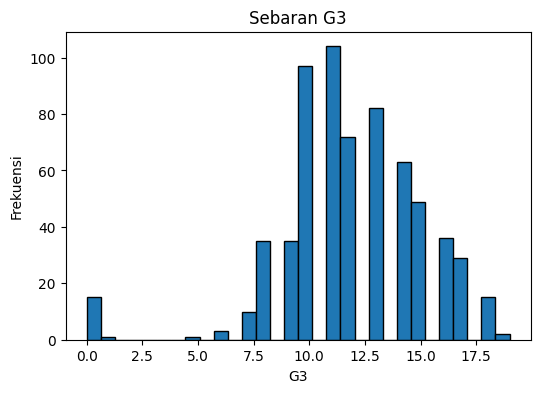

In [63]:
import matplotlib.pyplot as plt

# Grafik 1 — apakah sebaran target simetris?
plt.figure(figsize=(6, 4))
plt.hist(df_kerja[TARGET].dropna(), bins=30, edgecolor="black")
plt.xlabel(TARGET); plt.ylabel("Frekuensi")
plt.title(f"Sebaran {TARGET}")
plt.show()

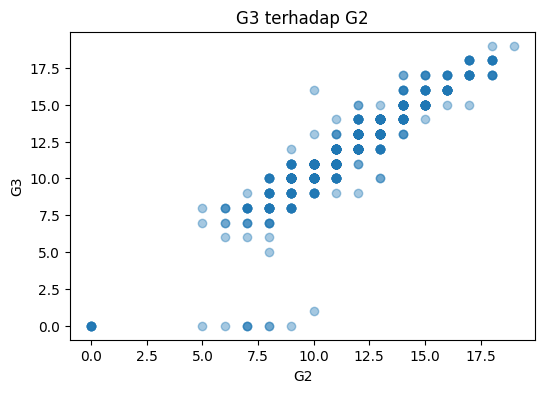

In [64]:
# Grafik 2 — apakah hubungannya satu garis lurus?
FITUR_KUAT = korelasi.index[1]        # indeks 0 adalah target itu sendiri

plt.figure(figsize=(6, 4))
plt.scatter(df_kerja[FITUR_KUAT], df_kerja[TARGET], alpha=0.4)
plt.xlabel(FITUR_KUAT); plt.ylabel(TARGET)
plt.title(f"{TARGET} terhadap {FITUR_KUAT}")
plt.show()

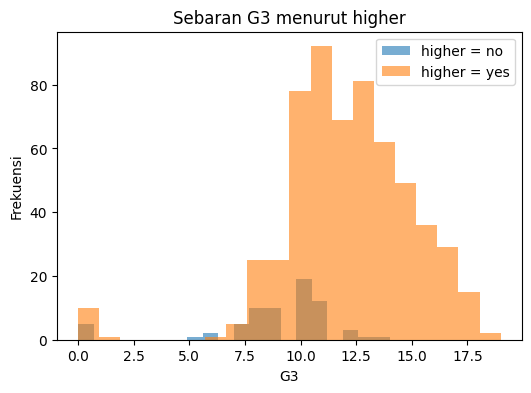

In [65]:
# Grafik 3 — variabel apa yang memisahkan kelompok pada grafik 2?
KOLOM_PEMISAH = "higher"

plt.figure(figsize=(6, 4))
for nilai in sorted(df_kerja[KOLOM_PEMISAH].unique()):
    bagian = df_kerja.loc[df_kerja[KOLOM_PEMISAH] == nilai, TARGET]
    plt.hist(bagian, bins=20, alpha=0.6, label=f"{KOLOM_PEMISAH} = {nilai}")
plt.xlabel(TARGET); plt.ylabel("Frekuensi"); plt.legend()
plt.title(f"Sebaran {TARGET} menurut {KOLOM_PEMISAH}")
plt.show()

### Keputusan preprocessing

- **Nilai hilang:** Tidak ada nilai hilang pada seluruh kolom (`0` nilai kosong / `0.0%` pada ke-33 kolom), sehingga tidak ada kolom yang dibuang karena data kosong.
- **Baris duplikat:** Ditemukan `0` baris duplikat persis pada dataset (`649` baris tetap utuh pada `df_bersih`).
- **Kardinalitas kategorik:** Seluruh `17` kolom kategorik memiliki jumlah kategori unik di bawah 20 (maksimal `5` kategori pada `Mjob` dan `Fjob`, `4` pada `reason`, `3` pada `guardian`, dan `2` kategori pada 13 kolom lainnya), sehingga aman langsung di-encode menggunakan `OneHotEncoder(handle_unknown="ignore")`.
- **Kemencengan target (`G3`):** Nilai skewness `G3` sebesar `-0.9129` (kemencengan negatif moderat mendekati `-1` akibat adanya `15` siswa dengan nilai akhir `0`), sehingga tidak dilakukan transformasi log (karena target bernilai `0` dan menceng ke kiri).
- **Pola hubungan utama:** Variabel `G2` (`r = 0.9185`) dan `G1` (`r = 0.8264`) memiliki korelasi linear positif yang sangat kuat terhadap `G3`, sedangkan riwayat ketidaklulusan (`failures`, `r = -0.3933`) berkorelasi negatif paling kuat terhadap nilai akhir.
- **Kolom yang dibuang dan alasannya:** Tidak ada kolom yang dibuang pada tahap ini (seluruh `32` fitur dipertahankan untuk pembuatan *baseline pipeline*; perbandingan model tanpa fitur `G1` dan `G2` akan diuji pada Pertemuan 13 jika diperlukan).

---
## Langkah E — Preprocessing di dalam Pipeline

Urutan empat langkah berikut tidak boleh ditukar. Menukar langkah 3 dan 4 menimbulkan
kebocoran data: statistik dari data uji ikut membentuk penskalaan, sehingga metrik di
Pertemuan 13 terlihat lebih bagus daripada kemampuan model sebenarnya.

In [66]:
from sklearn.model_selection import train_test_split

# 1. Pembersihan sesuai keputusan Langkah D
df_bersih = df_kerja.drop_duplicates()
df_bersih = df_bersih.dropna(subset=[TARGET])
# df_bersih = df_bersih.drop(columns=["nama_kolom"])   # aktifkan bila ada kolom dibuang

print("Baris sebelum:", len(df_kerja), "| sesudah:", len(df_bersih))

# 2. Pisahkan fitur dan target
X = df_bersih.drop(columns=[TARGET])
y = df_bersih[TARGET]

# 3. SPLIT sebelum transformasi apa pun
X_latih, X_uji, y_latih, y_uji = train_test_split(X, y, test_size=0.2, random_state=42)
print("Data latih:", X_latih.shape, "| Data uji:", X_uji.shape)

Baris sebelum: 649 | sesudah: 649
Data latih: (519, 32) | Data uji: (130, 32)


In [67]:
# 4. Kelompokkan kolom berdasarkan tipenya.
# Tulis include="number", bukan ["int64", "float64"]: bentuk pertama benar di versi pandas mana pun.
kolom_numerik = X_latih.select_dtypes(include="number").columns.tolist()
kolom_kategorik = X_latih.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerik  :", kolom_numerik)
print("Kategorik:", kolom_kategorik)

Numerik  : ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']
Kategorik: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [68]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

alur_numerik = Pipeline(steps=[
    ("imputasi", SimpleImputer(strategy="median")),   # median, bukan rata-rata: tahan nilai ekstrem
    ("skala", StandardScaler()),
])

alur_kategorik = Pipeline(steps=[
    ("imputasi", SimpleImputer(strategy="most_frequent")),
    # handle_unknown="ignore" WAJIB: tanpa ini aplikasi web error saat pengguna
    # memasukkan kategori yang tidak ada di data latih.
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", alur_numerik, kolom_numerik),
    ("kat", alur_kategorik, kolom_kategorik),
])

# Preprocessing + model dirangkai menjadi SATU objek
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regresi", LinearRegression()),
])

model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regresi', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('kat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If t

In [69]:
# Pemeriksaan: berapa kolom setelah one-hot encoding?
hasil = preprocessor.fit_transform(X_latih)

print("Kolom asli           :", X_latih.shape[1])
print("Setelah preprocessing:", hasil.shape[1])
print("\nPertambahannya berasal dari one-hot encoding kolom kategorik.")
print("Jika pertambahannya sangat besar (misalnya 12 menjadi 900), ada kolom")
print("berkardinalitas tinggi yang lolos dari Langkah D.")

Kolom asli           : 32
Setelah preprocessing: 58

Pertambahannya berasal dari one-hot encoding kolom kategorik.
Jika pertambahannya sangat besar (misalnya 12 menjadi 900), ada kolom
berkardinalitas tinggi yang lolos dari Langkah D.


---
## Langkah F — Simpan hasil ke Drive

Pertemuan 13 membaca berkas ini. Pastikan sel di bawah selesai tanpa galat sebelum
pertemuan berakhir.

In [70]:
import joblib

hasil_p12 = {
    "X_latih": X_latih, "X_uji": X_uji,
    "y_latih": y_latih, "y_uji": y_uji,
    "kolom_numerik": kolom_numerik,
    "kolom_kategorik": kolom_kategorik,
    "TARGET": TARGET,
    "model_belum_dilatih": model,      # Pipeline yang sudah dirancang, belum di-fit
    "sumber_dataset": f"https://www.kaggle.com/datasets/{SLUG}",
}

joblib.dump(hasil_p12, os.path.join(FOLDER, "p12_data.joblib"))
print("Tersimpan: p12_data.joblib")
print("Isi folder:", sorted(os.listdir(FOLDER)))

Tersimpan: p12_data.joblib
Isi folder: ['P12_Penyiapan_Data_Kelompok1.ipynb', 'data_mentah.csv', 'p12_data.joblib', 'p13_metrik.json', 'p13_model.joblib']


---
## Daftar periksa sebelum Pertemuan 12 berakhir

- [✓] Tabel identitas dan penanggung jawab terisi
- [✓] `df.shape` tercetak dan angkanya dicatat
- [✓] Enam pemeriksaan dan tiga grafik sudah dijalankan
- [✓] Sel keputusan preprocessing terisi **dengan angka**, bukan kalimat umum
- [✓] `train_test_split` berada di sel **sebelum** `Pipeline` dirakit
- [✓] `handle_unknown="ignore"` ada pada `OneHotEncoder`
- [✓] Sel Langkah F mencetak `Tersimpan: p12_data.joblib`

Kelompok yang belum mencentang seluruh butir menyelesaikannya sebagai tugas sebelum
Pertemuan 13, karena notebook Pertemuan 13 menolak berjalan tanpa `p12_data.joblib`.